# Expérimentations préliminaires — 3. LSTM (Keras)

Modèle temporel : au lieu de moyennes pré-calculées, le LSTM reçoit la **séquence** des
statistiques des 20 derniers matchs de chaque équipe (même saison, matchs strictement
antérieurs) et apprend lui-même à résumer la forme des équipes.

**Entrées.** Chaque pas de la séquence est un match passé de l'équipe, décrit par ses 529 statistiques. Prétraitement ajusté sur les équipes-matchs des saisons d'entraînement du pli
seulement : imputation (médiane) → standardisation (valeurs bornées à ±5 écarts-types) →
**ACP (critère de Kaiser, λ > 1)** → standardisation des composantes. On ajoute un indicateur
domicile/visiteur et un **indicateur de présence** (1 = vrai match) : les séquences plus
courtes que 20 (début de saison) sont rembourrées à gauche par des 0.

**Pourquoi l'ACP ?** Comme pour XGBoost, uniquement pour **alléger le modèle** : les 529 statistiques d'un match, très redondantes, sont remplacées par un nombre beaucoup plus petit
de composantes. La couche LSTM a alors beaucoup moins de poids (4 × 16 × (*p* + 16 + 1), où
*p* est le nombre de variables par pas), ce qui accélère l'entraînement et limite le
surapprentissage. Les composantes sont restandardisées (variance 1) pour que leurs échelles,
très différentes (λ₁ ≫ 1), ne déséquilibrent pas l'apprentissage. Un essai antérieur (ancien protocole, saisons 2020-21 à 2025-26) avec une ACP conservant
95 % de la variance avait donné une log loss de validation moins bonne (plis 2
et 5 : 0,678 et 0,687 avec ACP contre 0,660 et 0,678 sans) ; le critère de Kaiser est retenu
ici par cohérence avec les autres modèles. La redondance restante est gérée par un
**dropout de 30 % sur les entrées** et un encodeur de petite taille.

**Architecture** (volontairement petite, peu de données) :

1. dropout sur les entrées, puis un encodeur `LSTM` **partagé** (16 unités) lit la séquence de l'équipe locale et celle de
   l'équipe visiteuse → $\mathbf h_L$, $\mathbf h_V$ ;
2. une tête dense reçoit $[\mathbf h_L, \mathbf h_V, \mathbf h_L - \mathbf h_V]$ →
   `Dense(32, relu)` → `Dropout(0.3)` → `Dense(1, sigmoid)`.

**Entraînement** : AdamW (lr = 10⁻³, weight decay = 10⁻⁴), lots de 128, arrêt précoce sur la
validation interne (patience 10 époques), puis réentraînement sur tout l'entraînement du pli
pour le nombre d'époques retenu. Keras 3 est utilisé avec le moteur (*backend*) PyTorch.

**Protocole commun** (voir `src/nhl_forecast/features/equipes.py` et
`src/nhl_forecast/evaluation/preliminaire.py`) :

- saisons régulières **2009-10 à 2025-26**, statistiques d'**équipes** seulement, **toutes les
  colonnes** de `t_summary`, `t_percentages`, `t_summaryshooting`, `t_outshootoutshotby` et
  MoneyPuck (5 situations de jeu) ; seuls les identifiants, les colonnes vides ou constantes et
  les doublons exacts sont retirés, automatiquement ;
- validation **progressive** (*walk-forward*, fenêtre croissante) : chaque pli teste **une
  saison** et s'entraîne sur toutes les saisons antérieures ;
  - **développement** : plis 1 à 8, saisons testées 2016-17 à 2023-24 ;
  - **évaluation finale** : plis 9 et 10, saisons 2024-25 et 2025-26, réservées (à ne pas
    utiliser pour les choix de modélisation) ;
- hyperparamètres choisis sur les 20 % les plus récents des matchs d'entraînement du pli ;
- métriques : log loss, score de Brier, accuracy (seuil 0,5), résumées séparément pour chaque
  phase.

Écart avec le protocole proposé (initialisation 2005-06 à 2007-08, développement à partir de
2008-09) : MoneyPuck ne commence qu'en 2008-09, et `t_percentages` / `t_summaryshooting` en
2009-10. Les saisons 2005-06 à 2008-09 sont donc exclues de ce jeu de statistiques d'équipes ;
elles pourront servir à l'initialisation des modèles qui n'utilisent que les résultats (Elo).

Avec `SAUVER = True`, les tableaux sont enregistrés en CSV (séparateur « ; ») dans
`reports/map6009/tables/` (préfixe `exp_`) et les prédictions dans
`data/processed/experimentation/` (lues par `04_comparaison.ipynb`).

L'ancien protocole (2020-21 à 2025-26, une saison testée par pli ; rapport préliminaire 1) reste
disponible en définissant `NHL_EXP=base` avant les imports ; ses sorties sont suffixées `_base`
(`tables_base/`, `figures_base/`, `experimentation_base/`).

In [8]:
import os

os.environ["KERAS_BACKEND"] = "torch"  # avant l'import de keras

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from keras import layers
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

from nhl_forecast.evaluation.preliminaire import (
    FIG_DIR,
    GRAINE,
    ACPKaiser,
    exporter_tableau,
    formater,
    plis_chronologiques,
    predictions,
    resultats_par_pli,
    resume,
    sauver_predictions,
    separation_interne,
)
from nhl_forecast.features.equipes import (
    NOM_SAISON,
    charger_equipes,
    colonnes_stats,
    construire_matchs,
    indices_sequences,
)
from nhl_forecast.visualization.style import appliquer_style

SAUVER = True
LONGUEUR, CACHEE, DENSE, DROPOUT, DROPOUT_ENTREE = 20, 16, 32, 0.3, 0.3
LR, WEIGHT_DECAY, LOT, EPOQUES_MAX, PATIENCE = 1e-3, 1e-4, 128, 100, 10
appliquer_style()
print("Keras", keras.__version__, "– backend", keras.backend.backend())

Keras 3.15.1 – backend torch


In [3]:
eq = charger_equipes()
matchs = construire_matchs(eq)
STATS = colonnes_stats(eq)
idx = indices_sequences(eq, matchs, LONGUEUR)  # (n, 2, L) ; -1 = rembourrage
y = matchs["victoire_locale"].to_numpy().astype("float32")
plis = plis_chronologiques(matchs)
print(f"{len(matchs)} matchs, {len(STATS)} statistiques par match passé ; "
      f"part de pas réels : {(idx >= 0).mean():.1%}")

C:\Users\tom_9\Projets\nhl-probabilistic-forecasting\src\nhl_forecast\features\equipes.py:205: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  matchs = matchs.astype({"visiteur": "int64"}).reset_index()


20382 matchs, 529 statistiques par match passé ; part de pas réels : 86.5%


In [9]:
def preparer(pli):
    """Séquences (locale, visiteuse) ; prétraitement et ACP ajustés sur les saisons d'entraînement."""
    entr = eq["saison"].isin(pli["saisons_entr"]).to_numpy()
    pre = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(eq.loc[entr, STATS])
    z = np.clip(pre.transform(eq[STATS]), -5, 5)
    print(f"Pli {pli['pli']} – avant ACP : z {z.shape} (entraînement : {z[entr].shape})")
    acp = make_pipeline(ACPKaiser(random_state=GRAINE), StandardScaler()).fit(z[entr])
    z = acp.transform(z)
    print(f"Pli {pli['pli']} – après ACP : z {z.shape}")
    z = np.column_stack([z, 2 * eq["domicile"].to_numpy() - 1, np.ones(len(eq))])  # + présence
    z = np.vstack([z, np.zeros(z.shape[1])]).astype("float32")  # dernière ligne : rembourrage
    seq = z[np.where(idx >= 0, idx, len(z) - 1)]  # (n, 2, L, variables)
    print(f"Pli {pli['pli']} – séquences : {seq.shape}")
    return seq[:, 0], seq[:, 1], acp[0]


class Progression(keras.callbacks.Callback):
    """Barre de progression par époque, avec les pertes de la dernière époque."""

    def __init__(self, total, desc):
        super().__init__()
        self.total, self.desc = total, desc

    def on_train_begin(self, logs=None):
        self.barre = tqdm(total=self.total, desc=self.desc, unit="époque")

    def on_epoch_end(self, epoch, logs=None):
        self.barre.set_postfix({k: f"{v:.4f}" for k, v in (logs or {}).items()})
        self.barre.update()

    def on_train_end(self, logs=None):
        self.barre.total = self.barre.n  # arrêt précoce : la barre se termine à 100 %
        self.barre.refresh()
        self.barre.close()


def construire(n_var):
    keras.utils.set_random_seed(GRAINE)
    entree_l = keras.Input((LONGUEUR, n_var), name="local")
    entree_v = keras.Input((LONGUEUR, n_var), name="visiteur")
    dropout, encodeur = layers.Dropout(DROPOUT_ENTREE), layers.LSTM(CACHEE)  # partagés
    hl, hv = encodeur(dropout(entree_l)), encodeur(dropout(entree_v))
    x = layers.Concatenate()([hl, hv, layers.Subtract()([hl, hv])])
    x = layers.Dropout(DROPOUT)(layers.Dense(DENSE, activation="relu")(x))
    sortie = layers.Dense(1, activation="sigmoid")(x)
    modele = keras.Model([entree_l, entree_v], sortie)
    modele.compile(optimizer=keras.optimizers.AdamW(LR, weight_decay=WEIGHT_DECAY),
                   loss="binary_crossentropy")
    return modele

## 1. Entraînement par pli

In [4]:
preds, choix, acp, courbes = [], [], [], {}
for pli in plis:
    Xl, Xv, kaiser = preparer(pli)
#     print(f"Pli {pli['pli']} – Xl : {Xl.shape}")
#     print(f"Pli {pli['pli']} – Xv : {Xv.shape}")
    ajust, val = separation_interne(pli["entr"])
    # (a) arrêt précoce sur la validation interne
    m = construire(Xl.shape[-1])
    h = m.fit([Xl[ajust], Xv[ajust]], y[ajust], validation_data=([Xl[val], Xv[val]], y[val]),
              epochs=EPOQUES_MAX, batch_size=LOT, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True),
                         Progression(EPOQUES_MAX, f"Pli {pli['pli']} – arrêt précoce")])
    courbes[pli["pli"]] = pd.DataFrame(h.history)
    n_epoques = int(np.argmin(h.history["val_loss"]) + 1)
    # (b) réentraînement sur tout l'entraînement du pli, n_epoques époques
    m = construire(Xl.shape[-1])
    e = pli["entr"]
    m.fit([Xl[e], Xv[e]], y[e], epochs=n_epoques, batch_size=LOT, verbose=0,
          callbacks=[Progression(n_epoques, f"Pli {pli['pli']} – réentraînement")])
    p = m.predict([Xl[pli["test"]], Xv[pli["test"]]], verbose=0).ravel()
    preds.append(predictions(matchs, pli, p, "LSTM"))
    saison = NOM_SAISON[pli["saison_test"]]
    choix.append({"Pli": pli["pli"], "Saison testée": saison,
                  "Époques retenues": n_epoques,
                  "Log loss (validation)": min(h.history["val_loss"])})
    acp.append({"Pli": pli["pli"], "Saison testée": saison,
                "Composantes ACP": kaiser.n_components_,
                "Variance expliquée (%)": round(100 * kaiser.variance_expliquee_, 1),
                "Paramètres du modèle": m.count_params()})
preds = pd.concat(preds, ignore_index=True)
tab_choix = pd.DataFrame(choix)
tab_acp = pd.DataFrame(acp)
formater(tab_choix)

Pli 1 – avant ACP : z (40764, 529) (entraînement : (16200, 529))
Pli 1 – après ACP : z (40764, 90)
Pli 1 – séquences : (20382, 2, 20, 92)


Pli 1 – réentraînement: 100%|██████████| 5/5 [00:13<00:00,  2.74s/époque, loss=0.6870]


Pli 2 – avant ACP : z (40764, 529) (entraînement : (18660, 529))
Pli 2 – après ACP : z (40764, 89)
Pli 2 – séquences : (20382, 2, 20, 91)


Pli 2 – réentraînement: 100%|██████████| 2/2 [00:05<00:00,  2.97s/époque, loss=0.6941]


Pli 3 – avant ACP : z (40764, 529) (entraînement : (21202, 529))
Pli 3 – après ACP : z (40764, 90)
Pli 3 – séquences : (20382, 2, 20, 92)


Pli 3 – réentraînement: 100%|██████████| 9/9 [00:24<00:00,  2.72s/époque, loss=0.6695]


... (11 outputs left out)

Pli 9 – réentraînement: 100%|██████████| 10/10 [00:44<00:00,  4.45s/époque, loss=0.6647]


Pli 10 – avant ACP : z (40764, 529) (entraînement : (38140, 529))
Pli 10 – après ACP : z (40764, 90)
Pli 10 – séquences : (20382, 2, 20, 92)


Pli 10 – réentraînement: 100%|██████████| 9/9 [00:37<00:00,  4.14s/époque, loss=0.6657]


Pli,Saison testée,Époques retenues,Log loss (validation)
1,2016-17,5,0.6960
2,2017-18,2,0.6926
3,2018-19,9,0.6807
4,2019-20,9,0.6865
5,2020-21,9,0.6853
6,2021-22,8,0.6867
7,2022-23,9,0.6771
8,2023-24,9,0.6742
9,2024-25,10,0.6752
10,2025-26,9,0.6737


In [5]:
formater(tab_acp)

Pli,Saison testée,Composantes ACP,Variance expliquée (%),Paramètres du modèle
1,2016-17,90,88.0000,8577
2,2017-18,89,87.8000,8513
3,2018-19,90,88.0000,8577
4,2019-20,90,87.9000,8577
5,2020-21,91,88.1000,8641
6,2021-22,90,87.9000,8577
7,2022-23,90,87.9000,8577
8,2023-24,90,87.9000,8577
9,2024-25,90,87.9000,8577
10,2025-26,90,87.9000,8577


## 2. Résultats par pli

In [6]:
tab_plis = resultats_par_pli(preds)
if SAUVER:
    exporter_tableau(tab_plis, "exp_lstm_par_pli")
    exporter_tableau(tab_choix, "exp_lstm_hyperparametres")
    exporter_tableau(tab_acp, "exp_lstm_composantes")
    sauver_predictions(preds, "03_lstm")
formater(tab_plis)

Modèle,Pli,Phase,Saison testée,n,Log loss,Brier,Accuracy
LSTM,1,Développement,2016-17,1230,0.6858,0.2464,0.5488
LSTM,2,Développement,2017-18,1271,0.6860,0.2464,0.5649
LSTM,3,Développement,2018-19,1271,0.6879,0.2472,0.5531
LSTM,4,Développement,2019-20,1082,0.6916,0.2490,0.5564
LSTM,5,Développement,2020-21,868,0.6822,0.2442,0.5760
LSTM,6,Développement,2021-22,1312,0.6729,0.2401,0.5777
LSTM,7,Développement,2022-23,1312,0.6686,0.2379,0.5907
LSTM,8,Développement,2023-24,1312,0.6718,0.2395,0.5785
LSTM,9,Évaluation finale,2024-25,1312,0.6760,0.2414,0.5709
LSTM,10,Évaluation finale,2025-26,1312,0.6880,0.2472,0.5434


## 3. Résumé (moyenne ± écart-type sur les saisons testées, par phase)

In [7]:
tab_resume = resume(preds)
if SAUVER:
    exporter_tableau(tab_resume, "exp_lstm_resume")
formater(tab_resume)

Modèle,Phase,Saisons,Log loss,Brier,Accuracy
LSTM,Développement,8,0.6808 ± 0.0086,0.2438 ± 0.0041,0.5683 ± 0.0147
LSTM,Évaluation finale,2,0.6820 ± 0.0084,0.2443 ± 0.0041,0.5572 ± 0.0194


## 4. Courbe d'apprentissage (dernier pli)

Log loss sur l'ajustement (*training*, avec dropout) et sur la validation interne à chaque
époque. L'écart qui se creuse après quelques époques illustre le surapprentissage rapide sur
un petit jeu de données bruité.

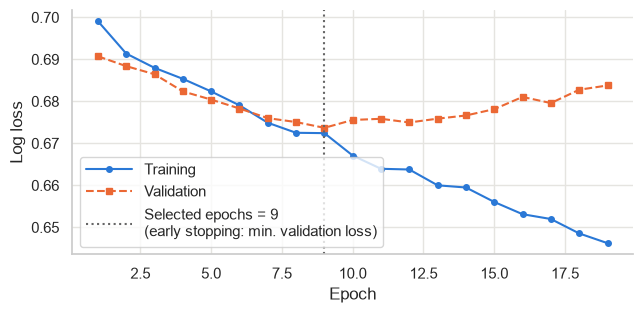

In [8]:
c = courbes[plis[-1]["pli"]]
ep = np.arange(1, len(c) + 1)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(ep, c["loss"], linestyle="-", marker="o", label="Training")
ax.plot(ep, c["val_loss"], linestyle="--", marker="s", label="Validation")
n_sel = tab_choix["Époques retenues"].iloc[-1]
ax.axvline(n_sel, color="0.4", linestyle=":", marker="",
           label=f"Selected epochs = {n_sel}\n(early stopping: min. validation loss)")
ax.set(xlabel="Epoch", ylabel="Log loss")
ax.legend()
fig.tight_layout()
if SAUVER:
    fig.savefig(FIG_DIR / "exp_lstm_apprentissage.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Schéma de l'architecture

Schéma du réseau testé (tracé à la main avec matplotlib à partir des constantes du notebook ;
nombre de variables par pas et de paramètres du dernier pli). Le même encodeur LSTM (mêmes
poids) lit la séquence de chaque équipe ; la tête dense combine $\mathbf h_L$, $\mathbf h_V$
et leur différence. Enregistré en PNG (300 ppp) et en SVG (vectoriel, pour PowerPoint).

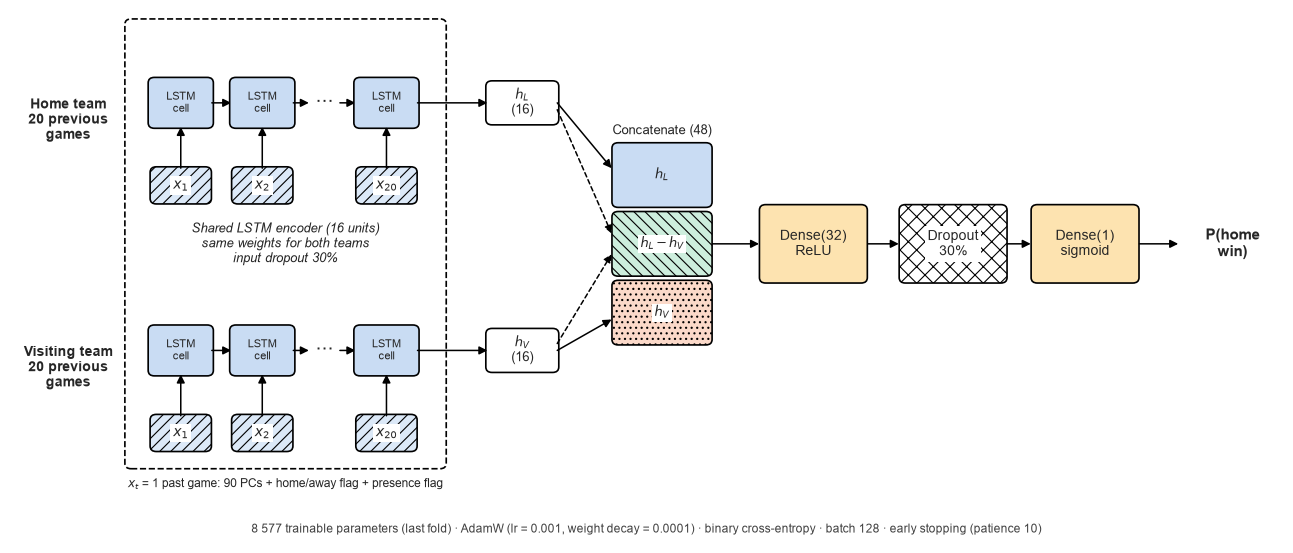

In [10]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

from nhl_forecast.evaluation.preliminaire import TABLE_DIR

# Sans réentraîner : nombre de composantes ACP du dernier pli, lu dans la table enregistrée
# (section 2) ; le modèle est seulement construit (non entraîné) pour compter ses paramètres.
n_cp = int(pd.read_csv(TABLE_DIR / "exp_lstm_composantes.csv", sep=";")["Composantes ACP"].iloc[-1])
n_var = n_cp + 2  # + indicateur domicile/visiteur + indicateur de présence
n_params = construire(n_var).count_params()


def boite(ax, x, y, l, h, texte, fc="white", hachure="", ls="-", taille=10, **kw):
    ax.add_patch(FancyBboxPatch((x - l / 2, y - h / 2), l, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec="black", hatch=hachure, linestyle=ls, linewidth=1.2, **kw))
    if texte:
        ax.text(x, y, texte, ha="center", va="center", fontsize=taille,
                bbox=dict(fc="white", ec="none", pad=2) if hachure else None)


def fleche(ax, xy1, xy2, ls="-", **kw):
    ax.add_patch(FancyArrowPatch(xy1, xy2, arrowstyle="-|>", mutation_scale=12, color="black",
                                 linewidth=1.1, linestyle=ls, shrinkA=0, shrinkB=0, **kw))


fig, ax = plt.subplots(figsize=(13, 5.6))
ax.set(xlim=(0, 16.4), ylim=(-0.9, 6.85))
ax.axis("off")
ax.grid(False)

# Encodeur LSTM partagé (cadre pointillé)
boite(ax, 3.55, 3.45, 4.1, 6.5, "", ls="--", fc="none")
ax.text(3.55, -0.05, f"$x_t$ = 1 past game: {n_cp} PCs + home/away flag + presence flag",
        ha="center", va="center", fontsize=8.5)
ax.text(3.55, 3.45, f"Shared LSTM encoder ({CACHEE} units)\nsame weights for both teams\n"
        f"input dropout {DROPOUT_ENTREE:.0%}", ha="center", va="center", fontsize=9, style="italic")

pas = [(2.2, "$x_1$"), (3.25, "$x_2$"), (4.85, f"$x_{{{LONGUEUR}}}$")]
for yc, equipe, h in [(5.25, "Home team", "$h_L$"), (1.65, "Visiting team", "$h_V$")]:
    ax.text(0.75, yc, f"{equipe}\n{LONGUEUR} previous\ngames", ha="center", va="center", fontsize=10,
            weight="bold")
    for i, (x, lab) in enumerate(pas):
        boite(ax, x, yc - 0.95, 0.75, 0.5, lab, fc="#dce9f8", hachure="///")    # entrée du pas
        boite(ax, x, yc + 0.25, 0.8, 0.7, "LSTM\ncell", fc="#c9dcf3", taille=8)  # cellule
        fleche(ax, (x, yc - 0.7), (x, yc - 0.1))
        if i < len(pas) - 1:
            x2 = pas[i + 1][0]
            if i == 1:
                ax.text((x + x2) / 2, yc + 0.25, "···", ha="center", va="center", fontsize=14)
                fleche(ax, (x + 0.4, yc + 0.25), (x + 0.6, yc + 0.25))
                fleche(ax, (x2 - 0.6, yc + 0.25), (x2 - 0.4, yc + 0.25))
            else:
                fleche(ax, (x + 0.4, yc + 0.25), (x2 - 0.4, yc + 0.25))
    boite(ax, 6.6, yc + 0.25, 0.9, 0.6, f"{h}\n({CACHEE})", fc="white", taille=9)
    fleche(ax, (5.25, yc + 0.25), (6.15, yc + 0.25))

# Concaténation [h_L, h_V, h_L - h_V] (h_L - h_V au centre pour éviter les croisements)
xc, segs = 8.4, [("$h_L$", "#c9dcf3", ""), ("$h_L - h_V$", "#cdeedd", "\\\\\\"), ("$h_V$", "#fbd9c9", "...")]
for k, (lab, fc, hach) in enumerate(segs):
    boite(ax, xc, 4.45 - k * 1.0, 1.25, 0.9, lab, fc=fc, hachure=hach, taille=9)
ax.text(xc, 5.0, f"Concatenate ({3 * CACHEE})", ha="center", va="bottom", fontsize=9)
fleche(ax, (7.05, 5.5), (xc - 0.65, 4.55))
fleche(ax, (7.05, 1.9), (xc - 0.65, 2.35))
fleche(ax, (7.05, 5.4), (xc - 0.65, 3.6), ls=(0, (3, 2)))
fleche(ax, (7.05, 2.0), (xc - 0.65, 3.3), ls=(0, (3, 2)))

# Tête dense
tete = [(10.35, f"Dense({DENSE})\nReLU", "#fde3b0", ""), (12.15, f"Dropout\n{DROPOUT:.0%}", "white", "xx"),
        (13.85, "Dense(1)\nsigmoid", "#fde3b0", "")]
fleche(ax, (xc + 0.65, 3.45), (tete[0][0] - 0.7, 3.45))
for i, (x, lab, fc, hach) in enumerate(tete):
    boite(ax, x, 3.45, 1.35, 1.1, lab, fc=fc, hachure=hach, taille=10)
    if i < len(tete) - 1:
        fleche(ax, (x + 0.7, 3.45), (tete[i + 1][0] - 0.7, 3.45))
fleche(ax, (14.55, 3.45), (15.05, 3.45))
ax.text(15.75, 3.45, "P(home\nwin)", ha="center", va="center", fontsize=11, weight="bold")

ax.text(8.2, -0.7, f"{n_params:,}".replace(",", " ") + f" trainable parameters (last fold) · AdamW (lr = {LR:g}, weight decay = "
        f"{WEIGHT_DECAY:g}) · binary cross-entropy · batch {LOT} · early stopping (patience {PATIENCE})",
        ha="center", va="center", fontsize=8.5, color="0.25")
fig.tight_layout()
if SAUVER:
    fig.savefig(FIG_DIR / "exp_lstm_architecture.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG_DIR / "exp_lstm_architecture.svg", bbox_inches="tight")  # vectoriel (PowerPoint)
plt.show()